In [1]:
%matplotlib inline

import random
import matplotlib.pyplot as plt
from copy import deepcopy
import numpy as np
import pystan 
import pandas as pd
import seaborn as sns
import math
import statistics as st
from matplotlib.backends.backend_pdf import PdfPages
import pickle
from tqdm.notebook import tqdm as tqdm

In [2]:
# Reduction data Import
datum = pd.read_csv('data/transportation/Static_LM_growth_lettuce.csv')
pd.set_option('display.max_rows', None)
print(datum)

    TIME     N    N0  Temp
0      0  3.38  3.36     5
1     24  3.36  3.36     5
2     48  3.61  3.36     5
3     72  3.66  3.36     5
4     96  4.21  3.36     5
5    120  4.50  3.36     5
6    144  4.36  3.36     5
7    168  4.66  3.36     5
8      0  3.43  3.43    10
9     24  3.43  3.43    10
10    48  3.62  3.43    10
11    54  3.85  3.43    10
12    60  4.12  3.43    10
13    72  4.64  3.43    10
14    96  4.81  3.43    10
15   120  4.81  3.43    10
16   144  4.81  3.43    10
17   168  4.80  3.43    10
18     0  3.37  3.32    15
19     4  3.32  3.32    15
20     5  3.36  3.32    15
21     6  3.33  3.32    15
22     7  3.43  3.32    15
23     8  3.59  3.32    15
24     9  3.58  3.32    15
25    10  3.57  3.32    15
26    11  3.66  3.32    15
27    12  3.62  3.32    15
28    13  3.58  3.32    15
29    14  3.77  3.32    15
30    15  3.94  3.32    15
31    16  3.87  3.32    15
32    17  4.08  3.32    15
33    18  3.91  3.32    15
34    19  4.39  3.32    15
35    20  4.20  3.32    15
3

In [3]:
#counts
S = datum.iloc[:,1]

#Time
t = datum.iloc[:,0]

#temperature
Temp = datum.iloc[:,3]

#初期菌数
I0 = datum.iloc[:,2]

#個数N
N = len(S) 

In [4]:
#dataset作る

dat_LM = {'N' : N, 't' : t, 'logC' : S, 'Temp' : Temp, 'logC0' : I0}

In [5]:
model = '''
data {
    int N;  // number of measurement cell
    real t[N];  // time
    real Temp[N];  // temperature
    real logC[N];  // measured cell
    real logC0[N]; // 10-log Initial number cell
}
transformed data{
    real lnC[N];  // measured cell
    real lnC0[N]; // natural log Initial number cell
    for (i in 1:N){
        lnC[i] = log(10)*logC[i];
        lnC0[i] = log(10)*logC0[i];
    }
}
parameters {
    real <lower = -2,upper = 2>  a;
    real <lower = 0,upper = 20> b;
    real <lower = 0,upper = 1>  c;
    real <lower = -2,upper = 5>  d;
    real <lower = 0> h0;
    real <lower = 0> sigma;   // measurement errors
}

transformed parameters{
    real alpha0;
    real <lower = 0,upper = 100> lnCmax[N];
    real mumax[N];
    real <lower = 0,upper = 100> lnC_mean[N];
    real lag[N];
    real A[N];
    
    alpha0  = exp(-h0);
    for (i in 1:N){
        lnCmax[i]  = a * Temp[i] + b ;
        mumax[i] = (c * (Temp[i]-d))^2;
        lag[i]   = (-log(alpha0))/mumax[i];
        A[i]     = t[i] + (1/mumax[i])*log(exp(-mumax[i]*t[i]) + exp(log(alpha0)) - exp(-mumax[i]*t[i]+log(alpha0)));
        lnC_mean[i]    = lnC0[i] + mumax[i]*A[i] - log(1 + (exp(mumax[i]*A[i])-1)/(exp(lnCmax[i]-lnC0[i]))); //Baranyi式
    }
}
    
model{
    c ~ normal(0.033, 0.01);
    d ~ normal(4.54, 1);
    sigma ~ cauchy(0, 0.5);
    for (i in 1:N){ 
        lnC[i] ~ normal(lnC_mean[i], sigma);
    }
}

'''

sm = pystan.StanModel(model_code=model)

with open('stan_model_growth_LM.pkl', 'wb') as f:

    pickle.dump(sm, f)

INFO:pystan:COMPILING THE C++ CODE FOR MODEL anon_model_ab2bc21516cfdf3ffb329affdd374384 NOW.
clang-12: warning: -Wl,-export_dynamic: 'linker' input unused [-Wunused-command-line-argument]
In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:836:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/arrayobject.h:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/ndarrayobject.h:12:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/ndarraytypes.h:1969:
/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/npy_1_7_deprecated_api.h:17:2: warning: "Using deprecated NumPy API, disable it with "          "#define NPY_NO_DEPRECATED_API NPY_1_7_API_VERSION" [-W#warnings]
#warning "Using deprecated NumPy API, dis

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

  call_assignment(dst, src, internal::assign_op<typename Dst::Scalar,typename Src::Scalar>());
  ^
/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/lib/eigen_3.3.3/Eigen/src/Eigenvalues/./Tridiagonalization.h:445:5: note: in instantiation of function template specialization 'Eigen::internal::tridiagonalization_inplace<Eigen::Matrix<double, -1, -1, 0>, Eigen::Matrix<double, -1, 1, 0>>' requested here
    tridiagonalization_inplace(mat,hCoeffs);
    ^
/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/lib/eigen_3.3.3/Eigen/src/Eigenvalues/./Tridiagonalization.h:430:52: note: in instantiation of function template specialization 'Eigen::internal::tridiagonalization_inplace_selector<Eigen::Matrix<double, -1, -1, 0>, -1, false>::run<Eigen::Matrix<double, -1, 1, 0>, Eigen::Matrix<double, -1, 1, 0>>' requested here
  tridiagonalization_inplace_selector<MatrixType>::run(mat, diag, subdiag, extractQ);
                                 

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmp_u2q665_/stanfit4anon_model_ab2bc21516cfdf3ffb329affdd374384_4061209254964518183.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

148 warnings generated.
ld: warning: -pie being ignored. It is only used when linking a main executable


In [6]:
# Sampling Baysian model of gastric reduction
sm = pickle.load(open('stan_model_growth_LM.pkl', 'rb'))
fit_LM = sm.sampling(
    data = dat_LM,
    iter = 25000+50000,
    chains = 4,
    warmup = 50000,
    thin = 10,
    seed = 1234
)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -3.2442, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -0.492115, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -2.84867, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial val

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -10, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -10, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Mess

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -0.00797437, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -0.0402999, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Inf

Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)


Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -0.205384, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -0.847513, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 50001 / 75000 [ 66%]  (Sampling)
Iteration: 50001 / 75000 [ 6

In [7]:
print(fit_LM)

Inference for Stan model: anon_model_ab2bc21516cfdf3ffb329affdd374384.
4 chains, each with iter=75000; warmup=50000; thin=10; 
post-warmup draws per chain=2500, total post-warmup draws=10000.

               mean se_mean     sd   2.5%    25%    50%    75%  97.5%  n_eff   Rhat
a              0.08  2.2e-4   0.02   0.03   0.06   0.08   0.09   0.12  10315    1.0
b             10.18  4.1e-3   0.41   9.43    9.9  10.17  10.45  11.03  10048    1.0
c              0.03  1.7e-5 1.7e-3   0.03   0.03   0.03   0.03   0.03   9953    1.0
d             -0.17  5.6e-3   0.56  -1.19  -0.55   -0.2   0.18   1.03  10124    1.0
h0             1.88  5.0e-3    0.5   0.94   1.54   1.86    2.2   2.92   9863    1.0
sigma          0.55  4.8e-4   0.05   0.46   0.51   0.54   0.58   0.66  10366    1.0
alpha0         0.17  8.7e-4   0.09   0.05   0.11   0.16   0.21   0.39   9901    1.0
lnCmax[1]     10.57  3.1e-3   0.31   10.0  10.36  10.56  10.77  11.23   9930    1.0
lnCmax[2]     10.57  3.1e-3   0.31   10.0  10.36  1

In [8]:
with open('fit_nuts_LM_growth.pkl', 'wb') as g:

    pickle.dump(fit_LM, g)

/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Pickling fit objects is an experimental feature!
The relevant StanModel instance must be pickled along with this fit object.
When unpickling the StanModel must be unpickled first.
  This is separate from the ipykernel package so we can avoid doing imports until


Progress:   0%|          | 0/105 [00:00<?, ?it/s]

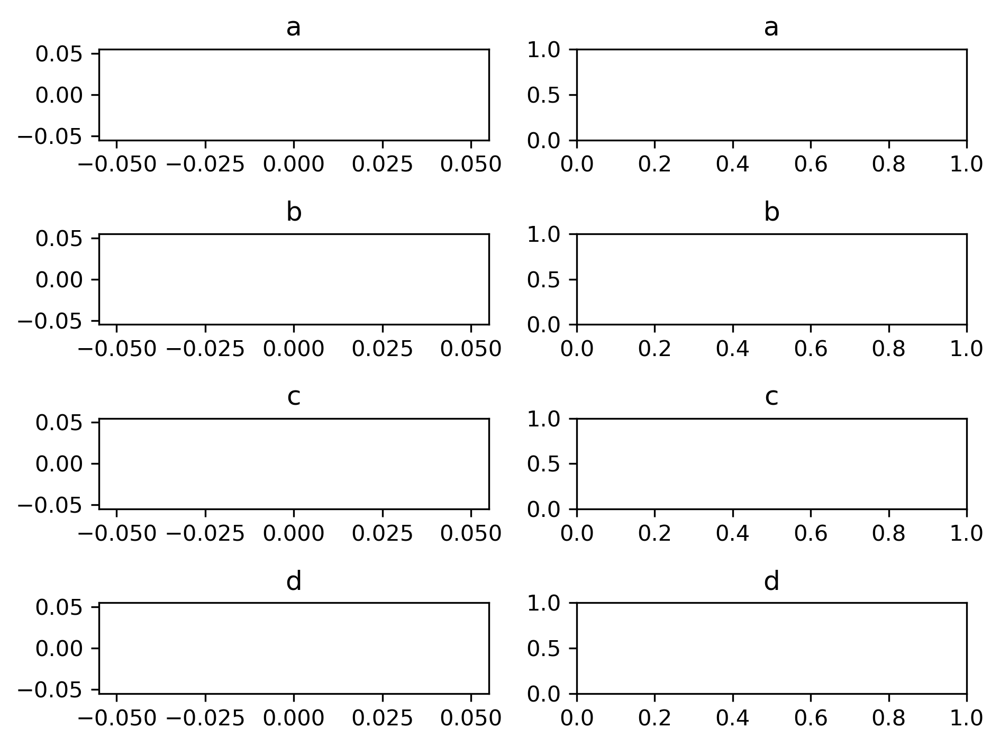

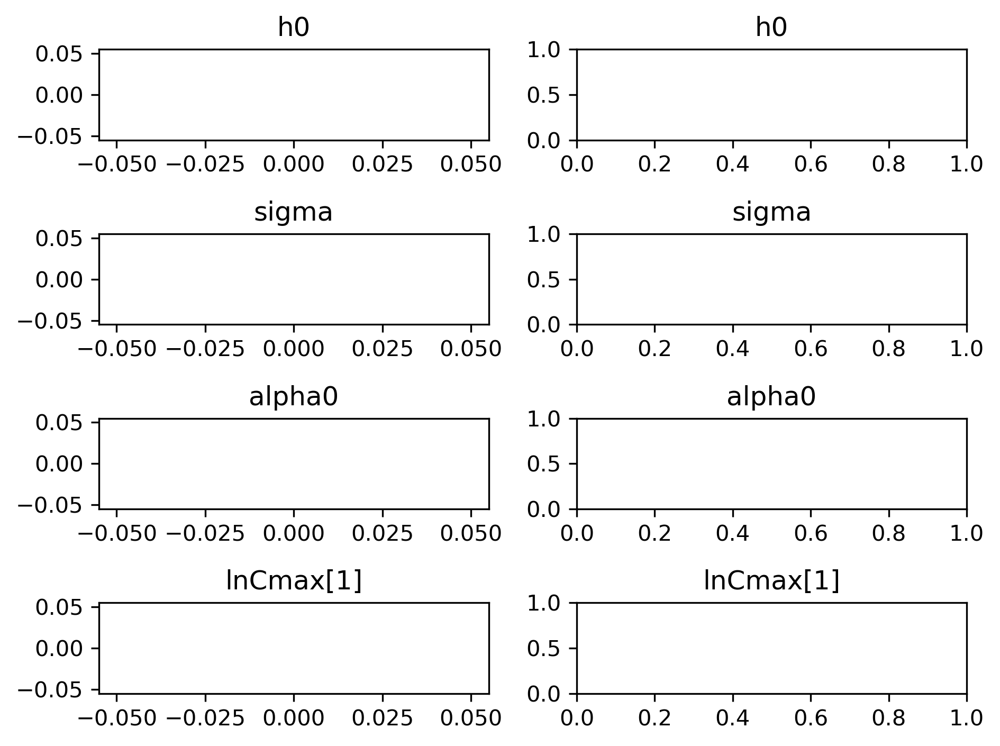

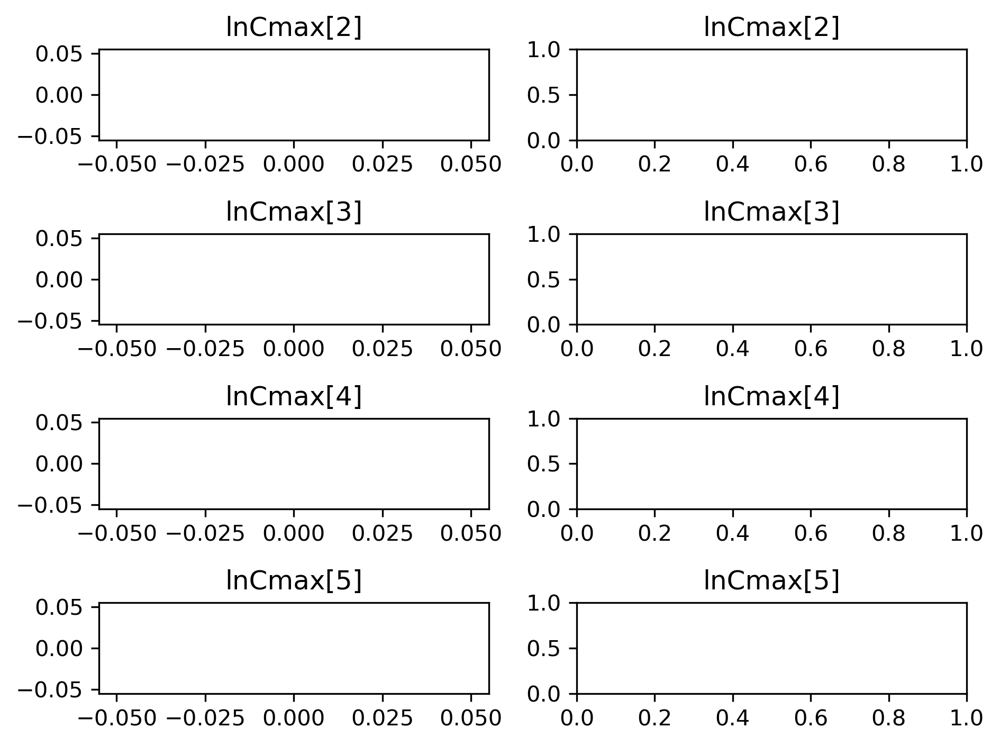

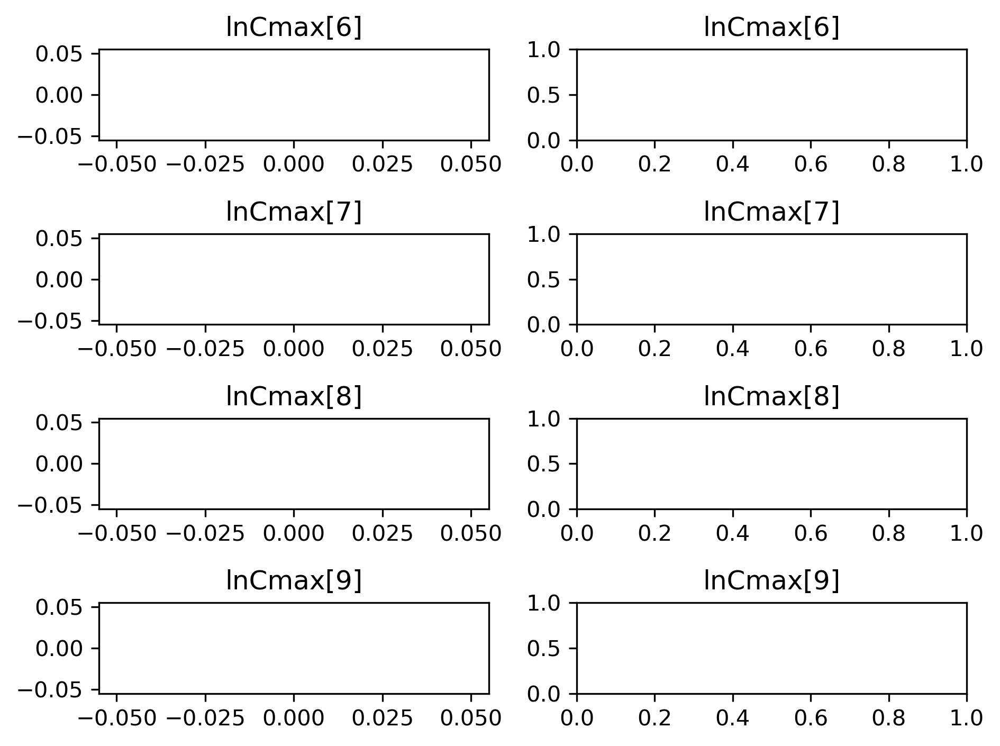

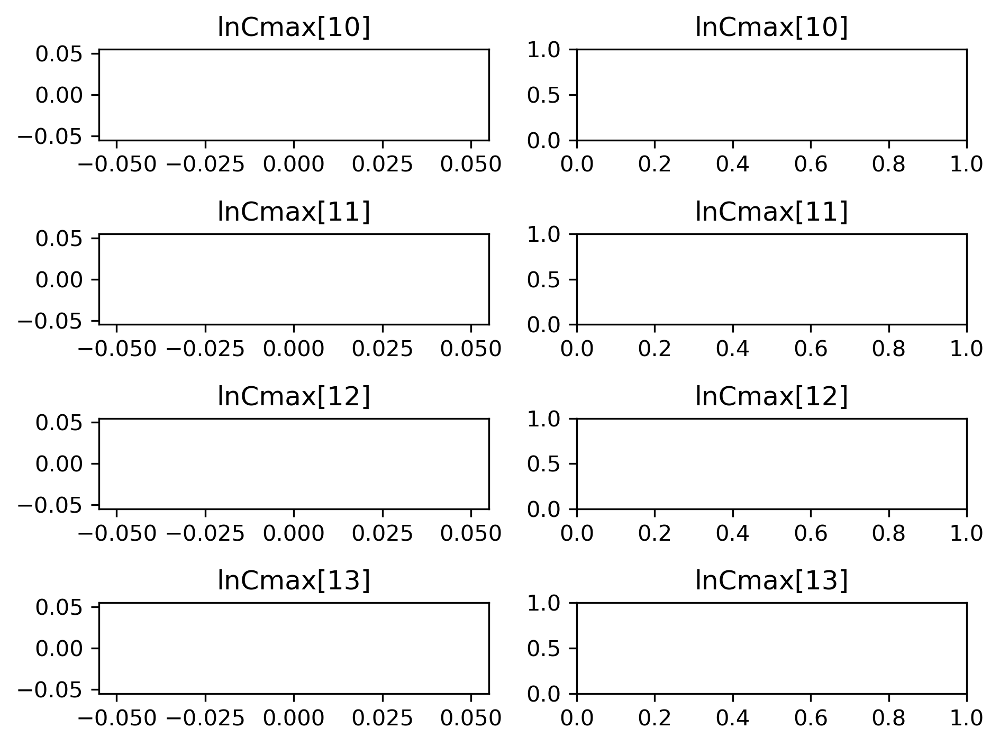

...

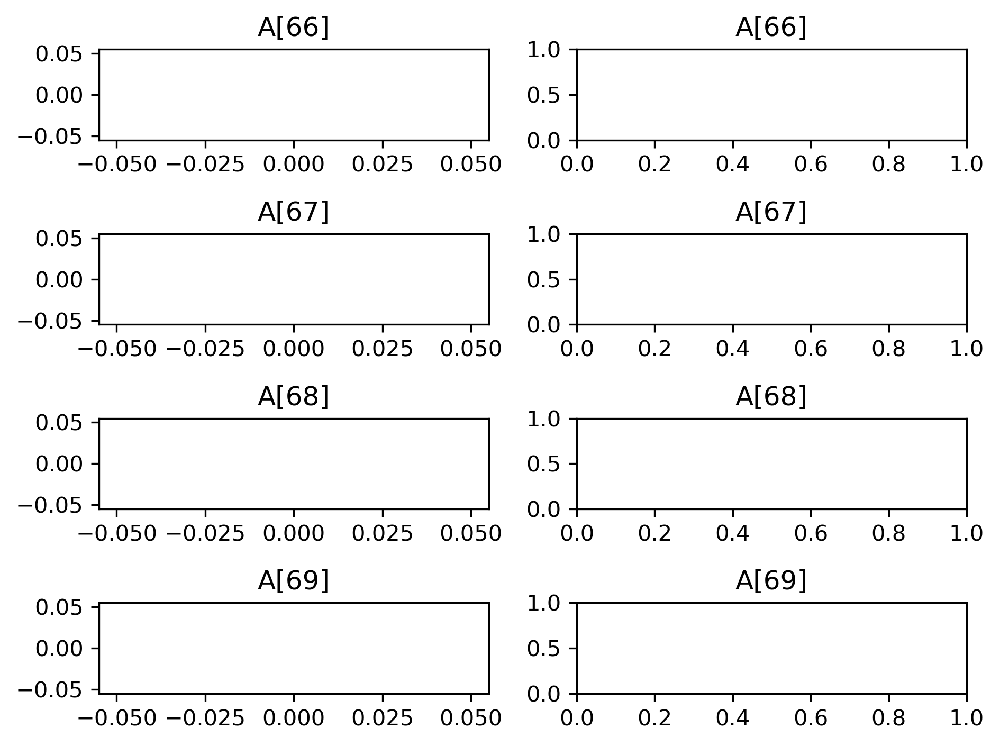

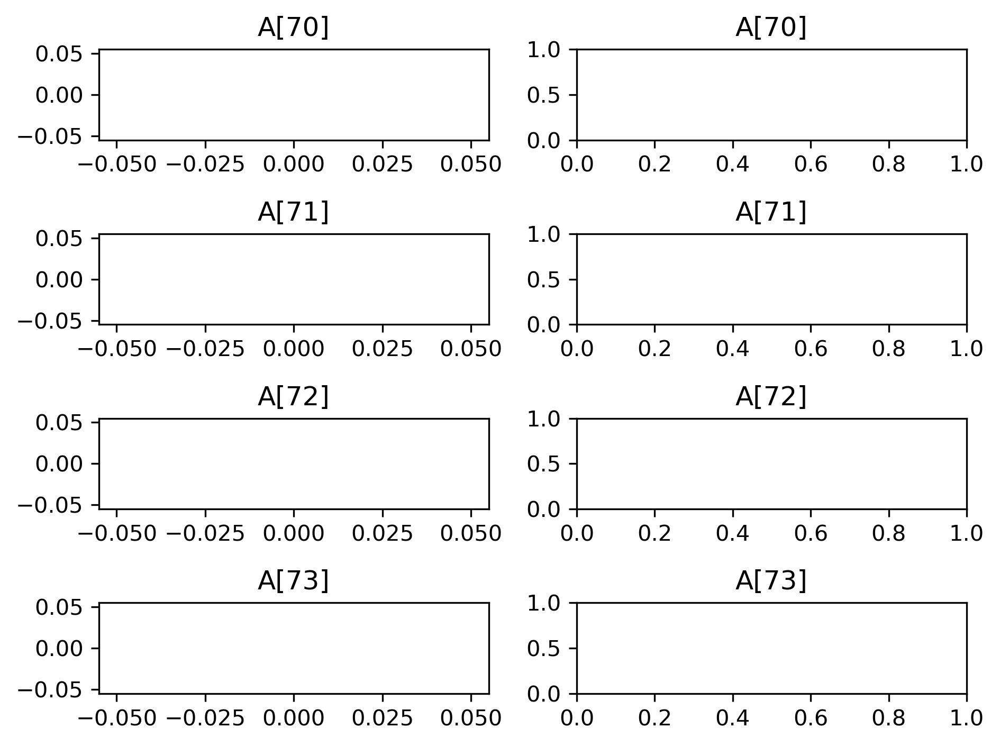

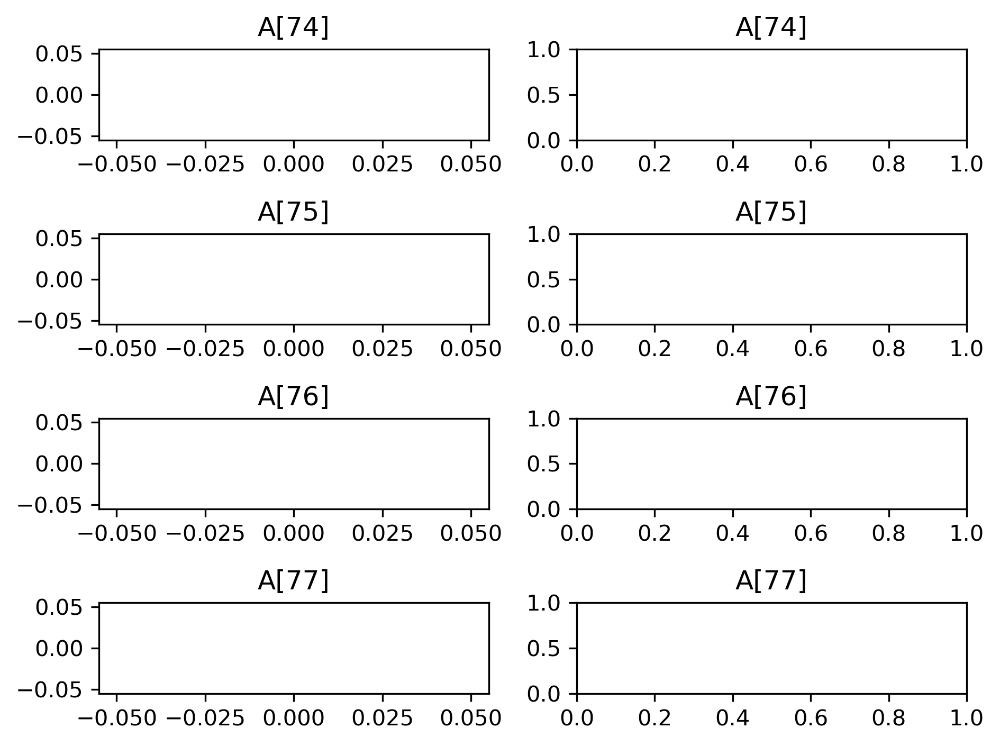

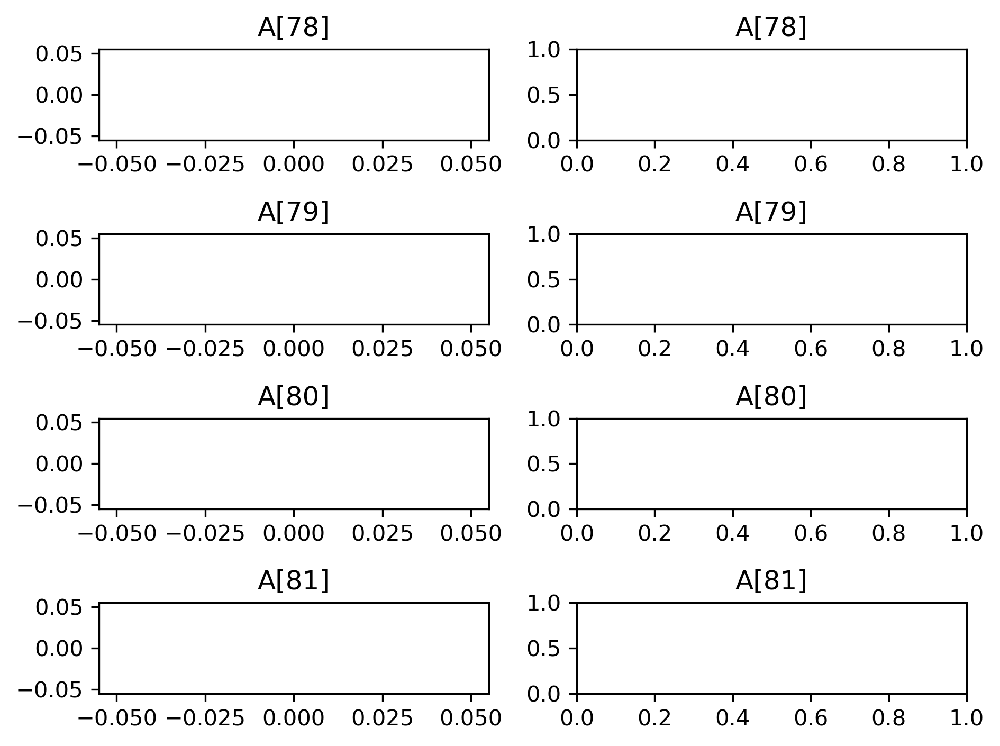

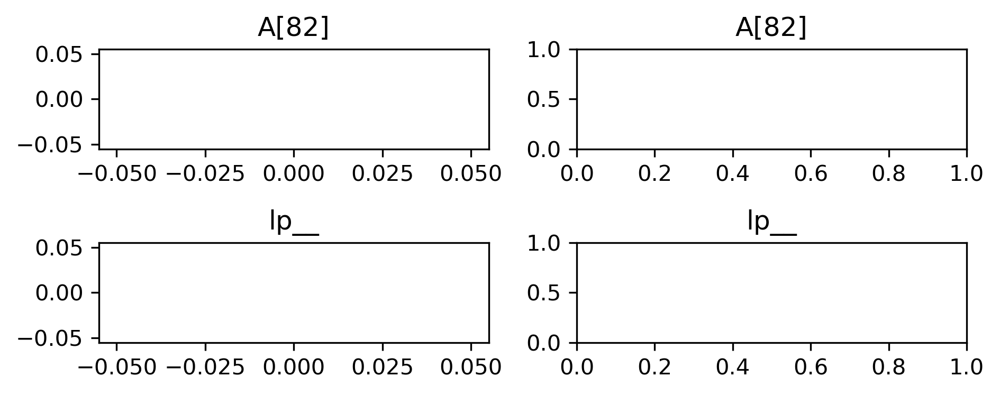

In [9]:
#計算過程を追跡する
samples = fit_LM.extract(permuted = False, inc_warmup = True)
paraname = fit_LM.sim["fnames_oi"]
palette = sns.color_palette()
ms = fit_LM.extract(permuted=False, inc_warmup=True)
iter_from = fit_LM.sim['warmup']
iter_range = np.arange(iter_from, ms.shape[0])
paraname = fit_LM.sim['fnames_oi']
num_pages = math.ceil(len(paraname)/4)

#結果を何個表示するかを指定
for pg in tqdm(range(num_pages),desc='Progress', leave=False):
    plt.figure(dpi=300)
    for pos in range(4):
        pi = pg*4 + pos
        if pi >= len(paraname): break
        plt.subplot(4, 2, 2*pos+1)
        plt.tight_layout()
        [plt.plot(iter_range + 1, ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])
        plt.subplot(4, 2, 2*(pos+1))
        plt.tight_layout()
        [sns.kdeplot(ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])

    plt.show()

In [10]:
def Fit_Model(Temp, c, d) :
    return (c * (Temp - d))
samples = fit_LM.extract(permuted=True)
temp_min = -5
temp_max = 30
devide = (temp_max-temp_min)*10
temp_interval = np.arange(temp_min, temp_max*(devide+1)/devide, 
                          (temp_max-temp_min)/devide, dtype="float")
Num_mcmc = len(samples["lp__"])
mu_conf_mcmc = np.zeros((len(temp_interval),Num_mcmc), dtype=float)
mu_conf_mcmc_quantile = np.zeros((len(temp_interval), 3), dtype=float)
mu_predict_mcmc = np.zeros((len(temp_interval),Num_mcmc), dtype=float)
mu_predict_mcmc_quantile = np.zeros((len(temp_interval), 3), dtype=float)
for j in tqdm(range(len(temp_interval)),desc='Progress', leave=False):
    for k in range(Num_mcmc):
        mu_conf_mcmc[j,k] = Fit_Model(temp_interval[j], samples["c"][k], samples["d"][k])

    mu_conf_mcmc_quantile[j,:] = np.quantile(mu_conf_mcmc[j,:],[0.025,  0.5, 0.975])

Progress:   0%|          | 0/351 [00:00<?, ?it/s]

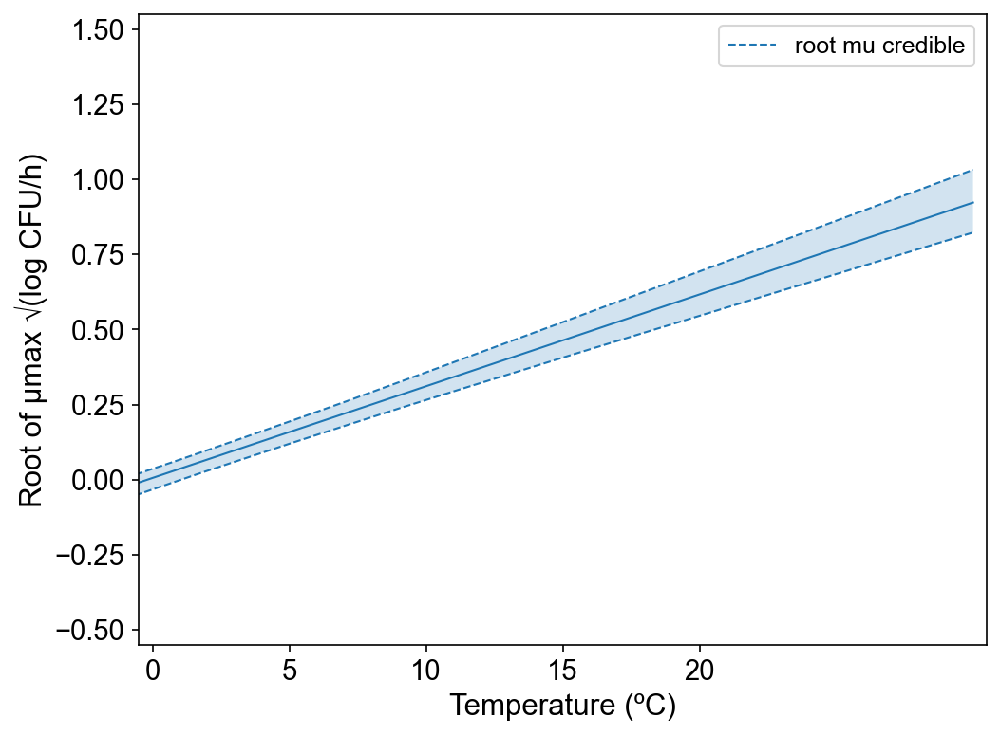

In [11]:
plt.figure(figsize=[6.4*1.2, 4.8*1.2], dpi=150)
plt.rcParams["font.family"] = "Arial"

plt.xticks(size=14)
plt.yticks(size=14)
plt.xlabel("Temperature (ºC)",size=15,fontname="Arial")
plt.ylabel("Root of µmax √(log CFU/h)",size=15,fontname="Arial")
plt.xticks(np.arange(-0, 21, 5))
plt.ylim([-0.55,1.55])
plt.xlim([-0.5,30.5])

Palette=sns.color_palette(n_colors = 3)
plt.fill_between(temp_interval, mu_conf_mcmc_quantile[:,0], mu_conf_mcmc_quantile[:,2], facecolor=Palette[0], alpha=0.2)
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,0], lw=1, color=Palette[0], linestyle='--')
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,2], lw=1, color=Palette[0], linestyle='--', label="root mu credible")
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,1], lw=1, color=Palette[0])
plt.legend(fontsize=12)

plt.show()

In [12]:
# A comparison of Listeria monocytogenes growth monitoring in ground pork samples by real-time polymerase chain reaction to conventional agar and most probable number methods
datum = pd.read_csv('data/transportation/Static_LM_growth_pork.csv')
pd.set_option('display.max_rows', None)
print(datum)

    TIME         N        N0  Temp
0      0  5.050584  5.050584     4
1     72  5.038911  5.050584     4
2    144  5.284047  5.050584     4
3    216  5.856031  5.050584     4
4    288  6.101167  5.050584     4
5    360  6.778210  5.050584     4
6    432  6.299611  5.050584     4
7    504  6.334630  5.050584     4
8    576  6.801556  5.050584     4
9    648  6.322957  5.050584     4
10   720  6.451362  5.050584     4
11   792  6.766537  5.050584     4
12   888  6.241245  5.050584     4
13  1008  6.813230  5.050584     4
14  1176  6.533074  5.050584     4
15  1344  6.603113  5.050584     4
16  1512  6.871595  5.050584     4
17     0  5.214008  5.214008     8
18    24  5.167315  5.214008     8
19    48  5.237354  5.214008     8
20    72  5.447471  5.214008     8
21    96  5.715953  5.214008     8
22   120  6.171206  5.214008     8
23   144  7.046693  5.214008     8
24   192  7.140078  5.214008     8
25   240  7.747082  5.214008     8
26   288  7.642023  5.214008     8
27   336  7.490272  

In [13]:
#counts
S = datum.iloc[:,1]

#Time
t = datum.iloc[:,0]

#temperature
Temp = datum.iloc[:,3]

#初期菌数
I0 = datum.iloc[:,2]

#個数N
N = len(S) 

In [14]:
#dataset作る

dat_LM = {'N' : N, 't' : t, 'logC' : S, 'Temp' : Temp, 'logC0' : I0}

In [15]:
# Sampling Baysian model of gastric reduction
sm = pickle.load(open('stan_model_growth_LM.pkl', 'rb'))
fit_LM = sm.sampling(
    data = dat_LM,
    iter = 25000+50000,
    chains = 4,
    warmup = 50000,
    thin = 10,
    seed = 1234567
)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -8.25523, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -0.877139, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial valu

Iteration:     1 / 75000 [  0%]  (Warmup)
Iteration:     1 / 75000 [  0%]  (Warmup)
Iteration:     1 / 75000 [  0%]  (Warmup)


Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -8, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -8, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Messag

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -2.49912, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -1.01827, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informat

Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (

In [16]:
print(fit_LM)

Inference for Stan model: anon_model_ab2bc21516cfdf3ffb329affdd374384.
4 chains, each with iter=75000; warmup=50000; thin=10; 
post-warmup draws per chain=2500, total post-warmup draws=10000.

               mean se_mean     sd   2.5%    25%    50%    75%  97.5%  n_eff   Rhat
a              0.02  1.7e-4   0.02-7.3e-3   0.01   0.02   0.04   0.06   9970    1.0
b             17.37  3.5e-3   0.35  16.68  17.13  17.36   17.6  18.07  10039    1.0
c              0.02  1.0e-5 1.0e-3   0.02   0.02   0.02   0.02   0.02   9514    1.0
d              0.61  2.6e-3   0.26   0.05   0.46   0.63    0.8   1.06  10082    1.0
h0             0.52  3.5e-3   0.35   0.03   0.25   0.46   0.72   1.33   9946    1.0
sigma          0.73  5.5e-4   0.05   0.63   0.69   0.72   0.76   0.84   9937    1.0
alpha0         0.63  2.0e-3   0.19   0.26   0.49   0.63   0.78   0.97   9824    1.0
lnCmax[1]     17.47  2.9e-3   0.29   16.9  17.27  17.47  17.66  18.05  10060    1.0
lnCmax[2]     17.47  2.9e-3   0.29   16.9  17.27  1

In [17]:
with open('fit_nuts_LM_growth_pork.pkl', 'wb') as g:

    pickle.dump(fit_LM, g)

/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Pickling fit objects is an experimental feature!
The relevant StanModel instance must be pickled along with this fit object.
When unpickling the StanModel must be unpickled first.
  This is separate from the ipykernel package so we can avoid doing imports until


Progress:   0%|          | 0/121 [00:00<?, ?it/s]

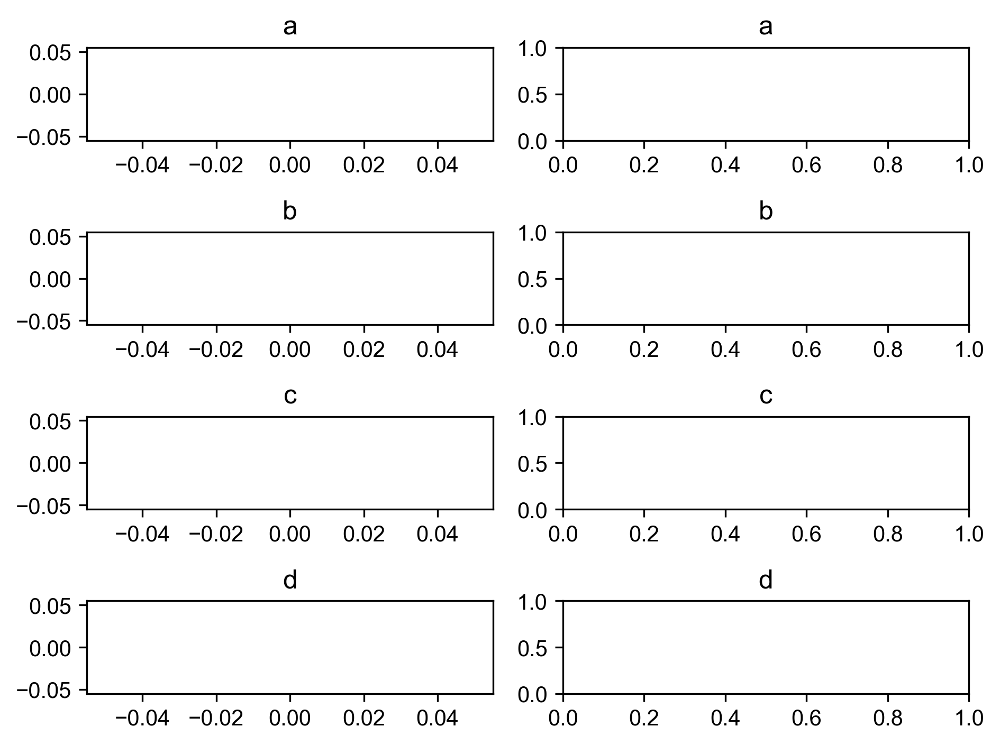

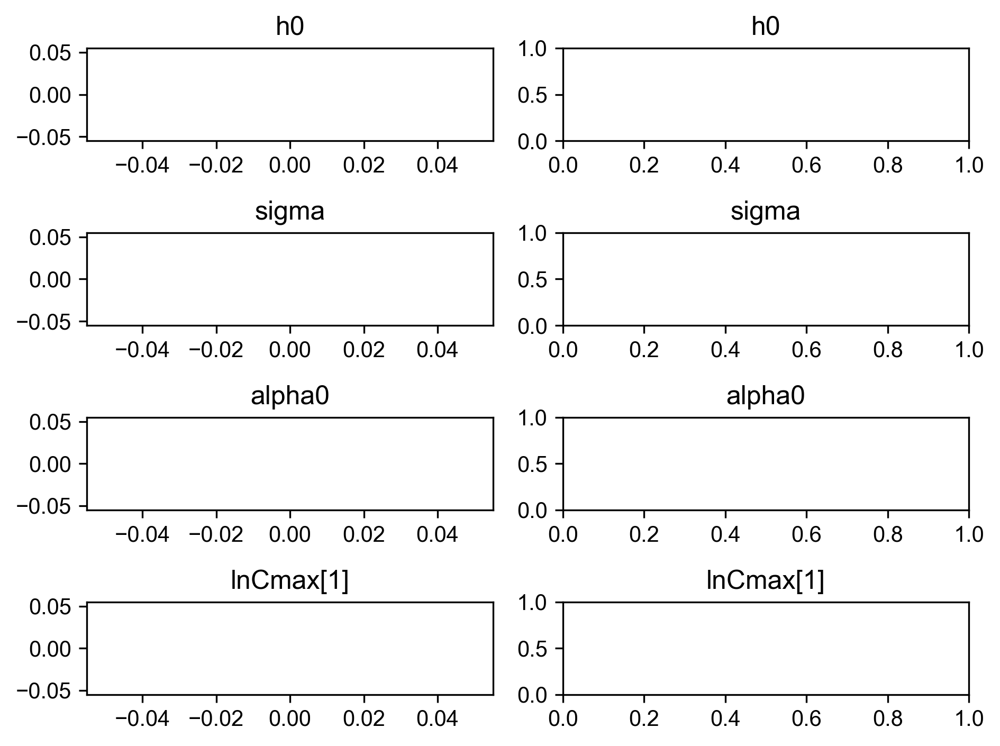

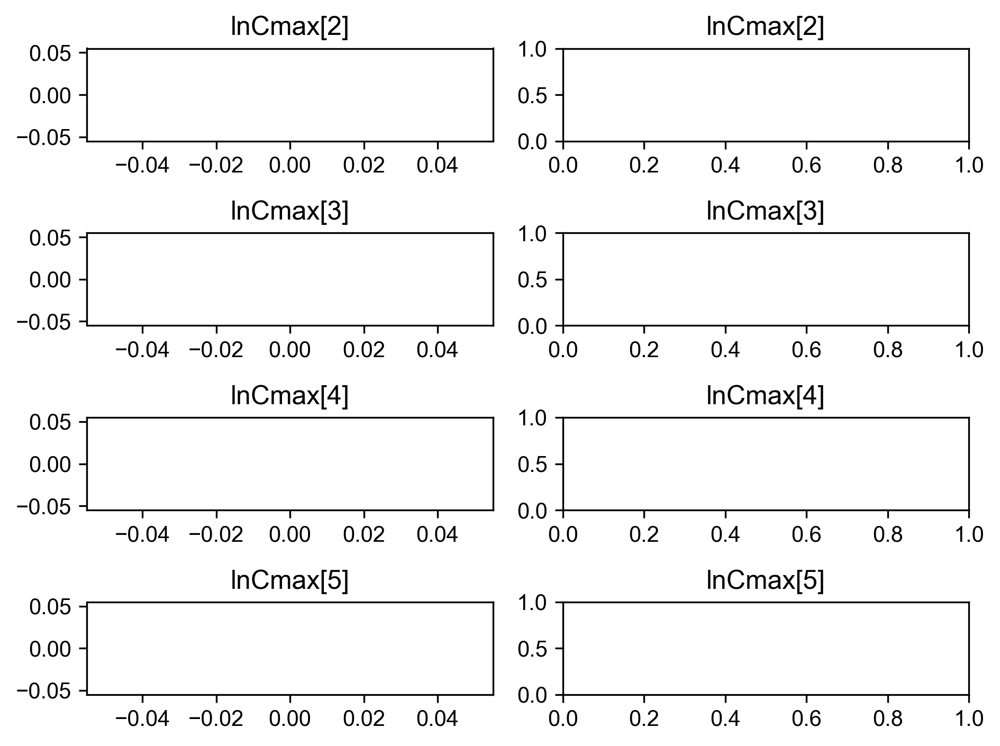

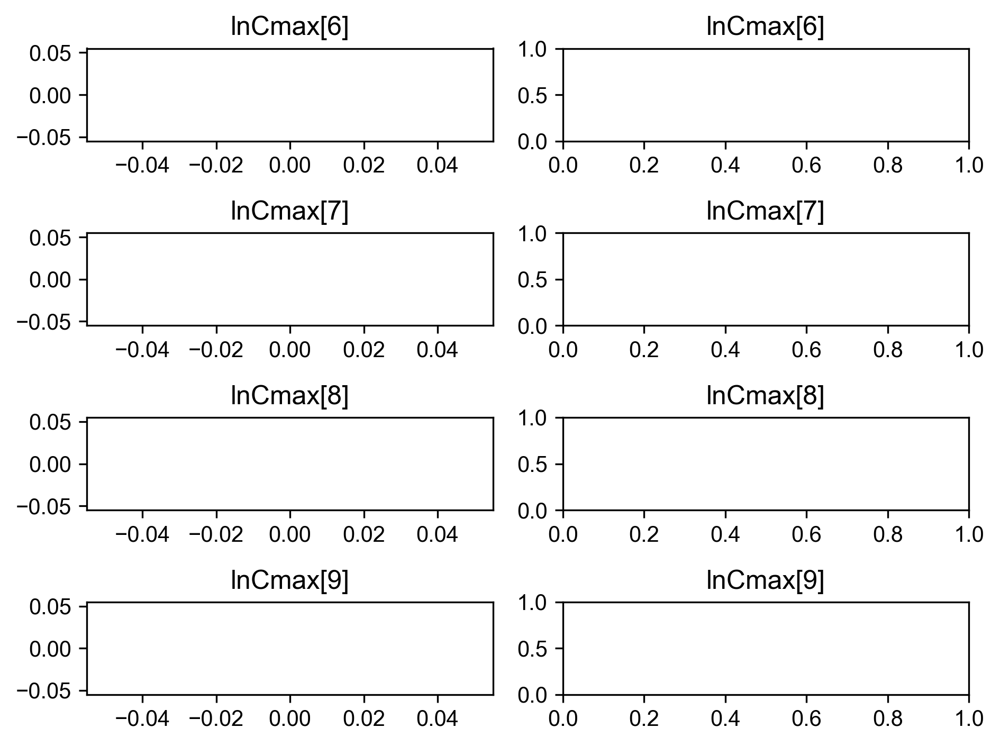

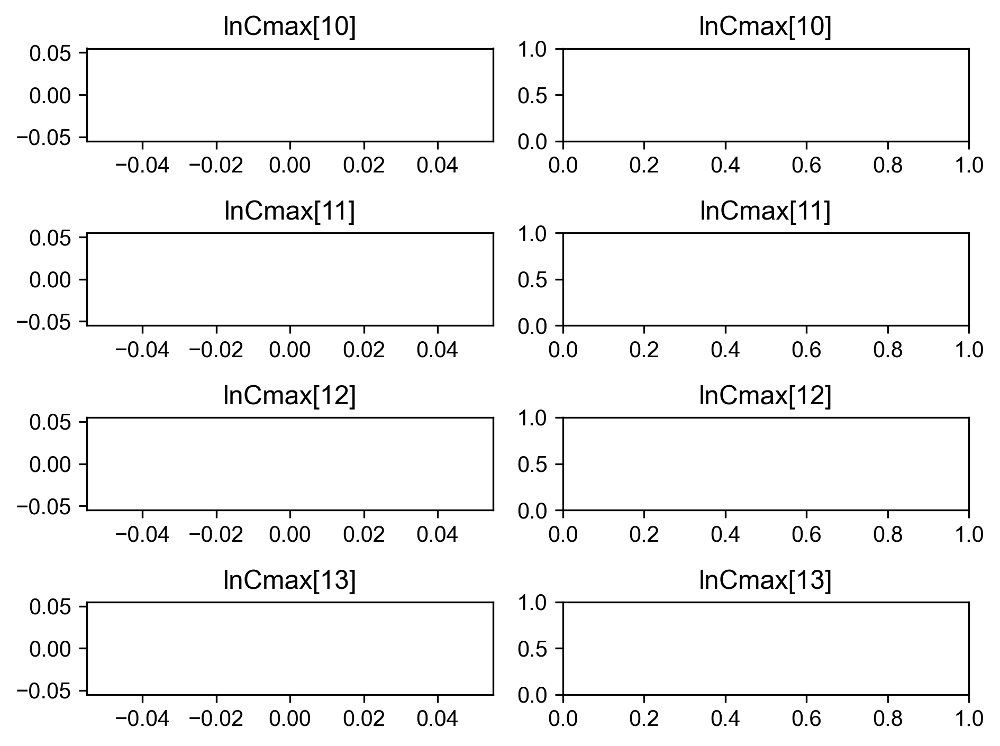

...

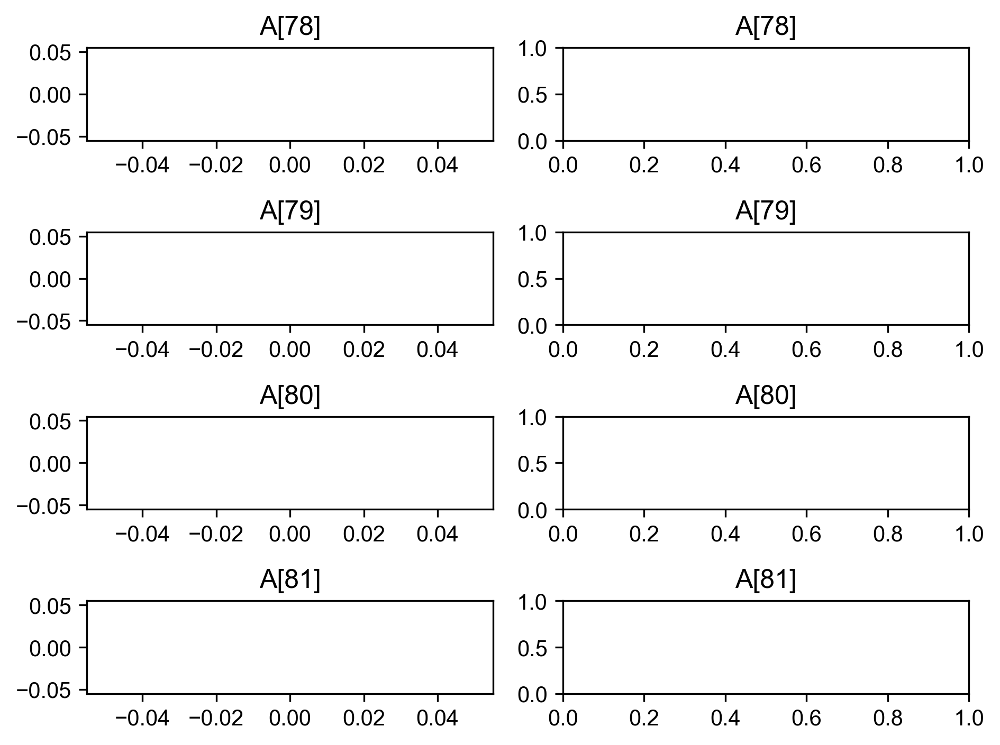

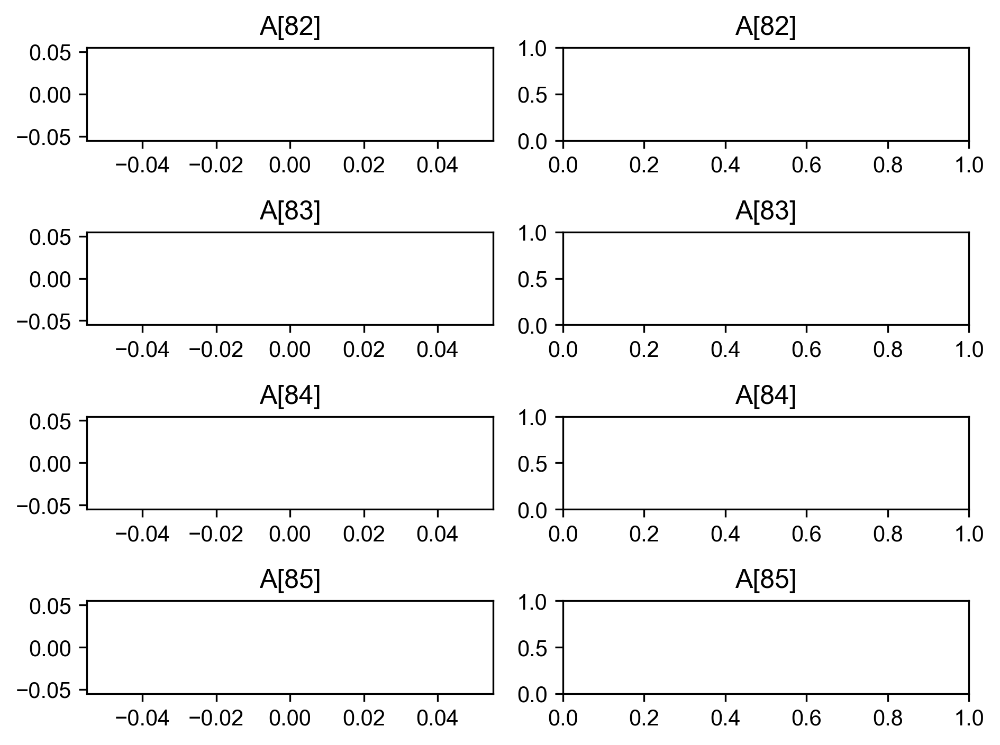

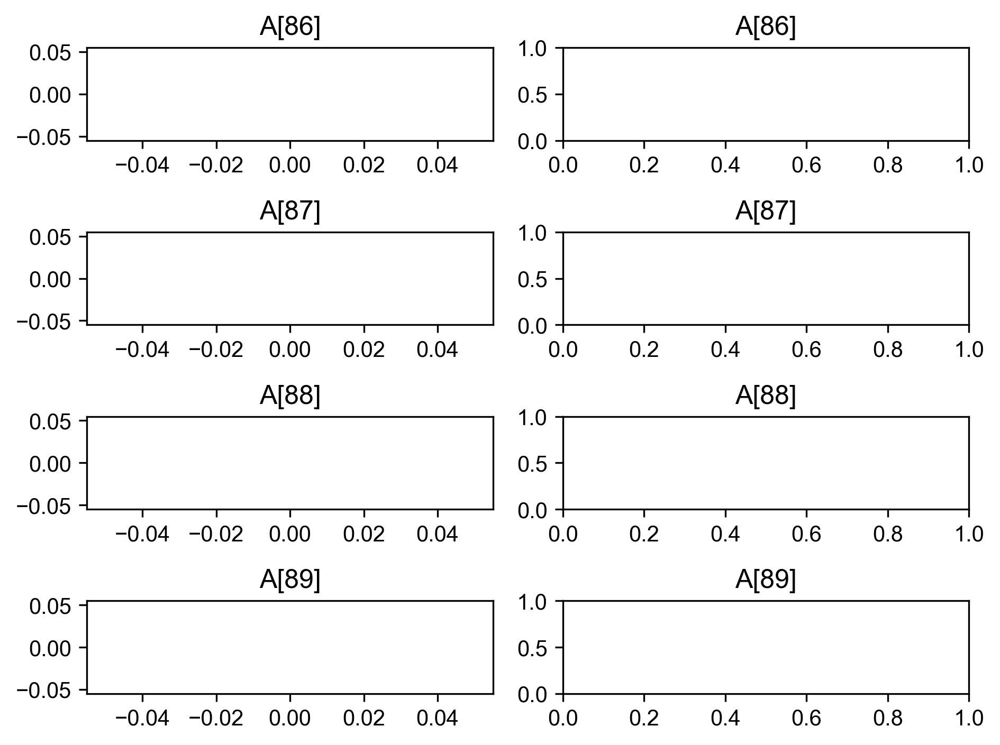

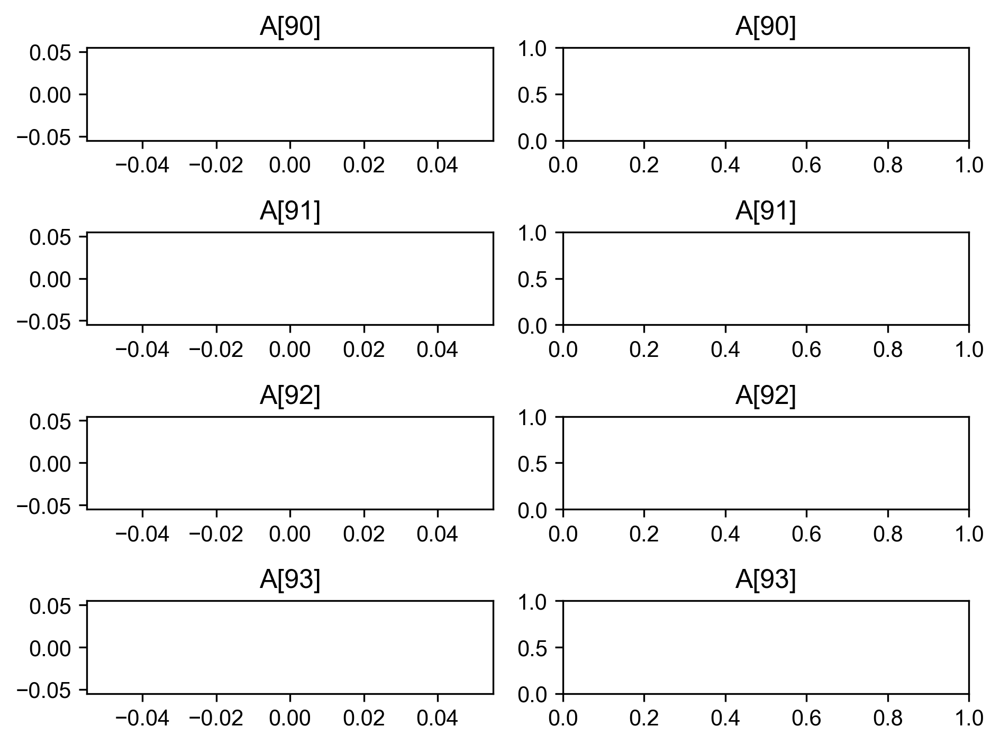

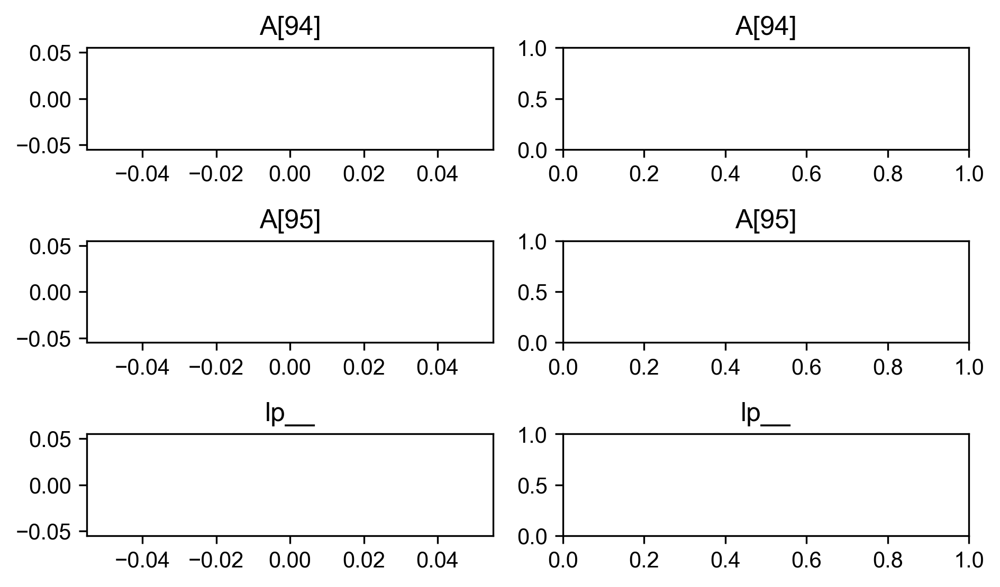

In [18]:
#計算過程を追跡する
samples = fit_LM.extract(permuted = False, inc_warmup = True)
paraname = fit_LM.sim["fnames_oi"]
palette = sns.color_palette()
ms = fit_LM.extract(permuted=False, inc_warmup=True)
iter_from = fit_LM.sim['warmup']
iter_range = np.arange(iter_from, ms.shape[0])
paraname = fit_LM.sim['fnames_oi']
num_pages = math.ceil(len(paraname)/4)

#結果を何個表示するかを指定
for pg in tqdm(range(num_pages),desc='Progress', leave=False):
    plt.figure(dpi=300)
    for pos in range(4):
        pi = pg*4 + pos
        if pi >= len(paraname): break
        plt.subplot(4, 2, 2*pos+1)
        plt.tight_layout()
        [plt.plot(iter_range + 1, ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])
        plt.subplot(4, 2, 2*(pos+1))
        plt.tight_layout()
        [sns.kdeplot(ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])

    plt.show()